 # RAG Agents

We have two major problems:

1. **LLMs can forget old conversations**

If we have a long conversation with an LLM, it may gradually lose access to older parts of the conversation. As the conversation becomes longer, the older information may no longer fit within the model's context, so the LLM may not remember things we discussed earlier.

2. **Sending large documents repeatedly can use more input tokens**

Suppose we want to know our company's leave policy. We upload the entire company PDF to ChatGPT, but we only need information about the leave policy.

If the PDF is very large, sending the entire document to the LLM as context can use a lot of input tokens. In a paid API-based application, processing unnecessary tokens can increase the cost.

So instead of sending the entire PDF every time, we can use **RAG (Retrieval-Augmented Generation)** to retrieve only the relevant information from the document and send that relevant information to the LLM.


    OWN Word explaination
hamare pass 2 bade problems h
Problem 1) agar ham apne LLMs se jyada baat karte h to wo bhool jaata h old conversation dhire dhire piche  ki baate bhoolta jaata h

Problem 2) suppose hame apne company ki leave policy jaan ni h uske liye hamne apna pura pdf chatgpt ko bheja ab sirf leave policy ke liye bada pdf bhejna sahi h uske liye hamare input tokens jayada use hoga jis se jab chatGPT paid hoga tab infuture aisa krne per hamra Bill jyada aayega


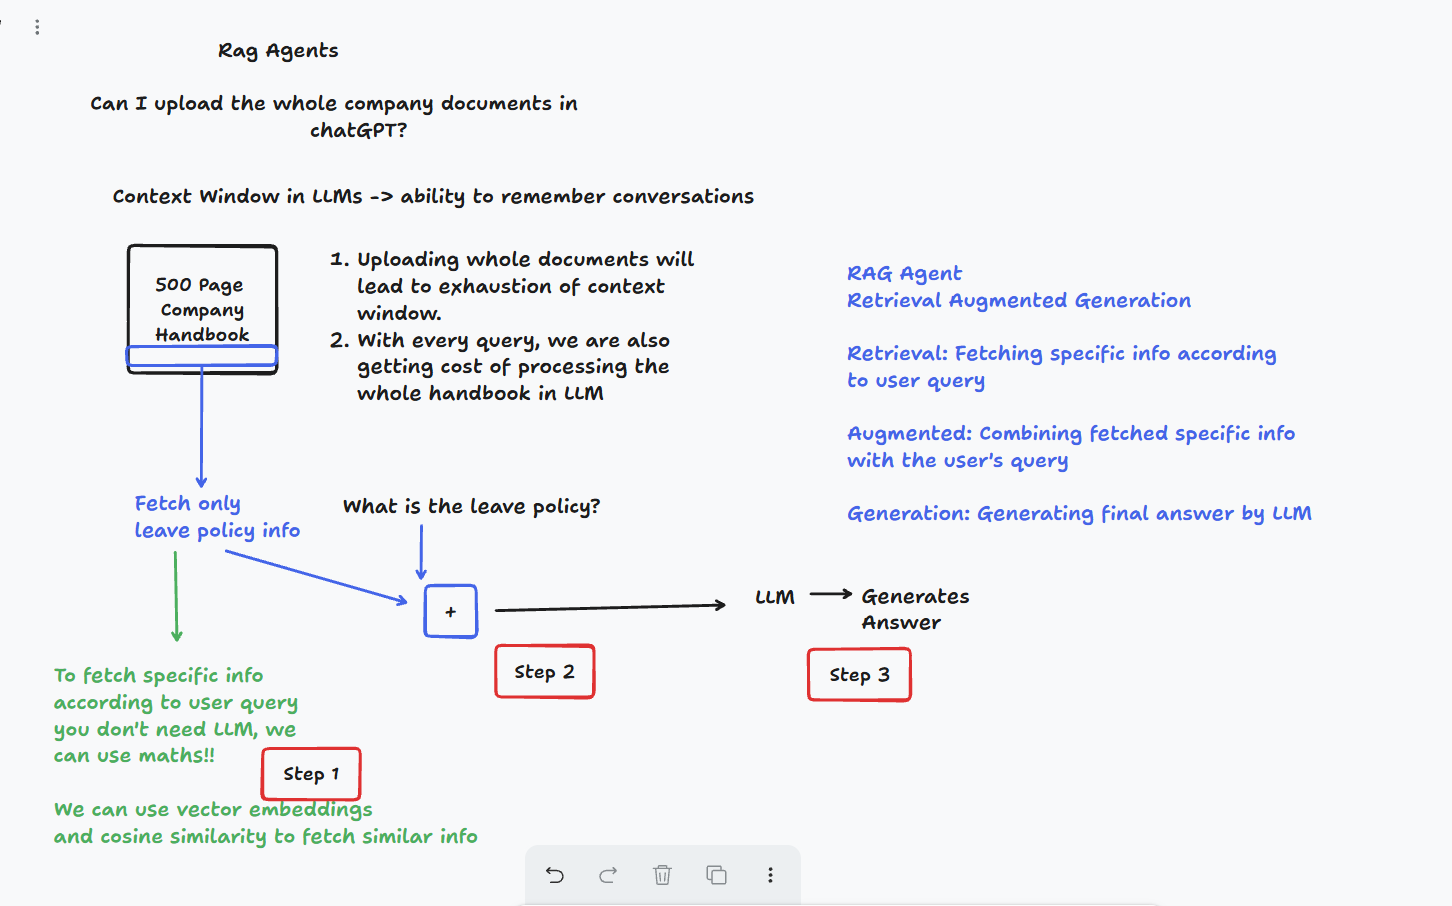

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/Rag Image.png.png"))

In [ ]:
# Small example first -> Enbeddings

In [ ]:
pip install -U langchain-huggingface -q

In [ ]:
#huggingface is machine learninfg model

#Hugging Face → text ko vector mein convert karta hai → RAG ko relevant information dhoondne mein help karta hai.
#Aur all-MiniLM-L6-v2 ek embedding model hai jo ye conversion karta hai.

In [ ]:
from langchain_huggingface import HuggingFaceEmbeddings # use to generate vector embeddings

In [ ]:
embedder = HuggingFaceEmbeddings(model_name='all-MiniLM-L6-v2') # ML Model to generate vector embeddings

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [ ]:
result = embedder.embed_query('What is machine learning?')
result

[-0.019954556599259377,
 0.009878002107143402,
 0.010249638929963112,
 0.02955370768904686,
 0.027186447754502296,
 -0.0192965567111969,
 -0.02412959188222885,
 -0.037735726684331894,
 -0.041054174304008484,
 -0.001474980148486793,
 -0.07607672363519669,
 0.036872074007987976,
 0.05372385308146477,
 -0.07053526490926743,
 -0.08609345555305481,
 0.02100684493780136,
 -0.04226336628198624,
 0.02844890207052231,
 -0.038375373929739,
 -0.06591919809579849,
 0.013949654996395111,
 0.01227535679936409,
 -0.06821976602077484,
 0.02862507477402687,
 0.014761180616915226,
 0.03223143890500069,
 0.008694231510162354,
 0.013062074780464172,
 -0.015726709738373756,
 0.018896568566560745,
 0.020023854449391365,
 -0.03929707035422325,
 0.01564716175198555,
 0.03339807316660881,
 -0.07339105755090714,
 0.05935782566666603,
 -0.01238581445068121,
 0.02458464726805687,
 0.020107125863432884,
 -0.020254528149962425,
 -0.050247713923454285,
 -0.09044118970632553,
 -0.015374385751783848,
 -0.0036124335601

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

e1 = embedder.embed_query('I love cricket')
e2 = embedder.embed_query('Cricket is my favourite sport')
e3 = embedder.embed_query('Machine learning is the most advanced field')

In [ ]:
cosine_similarity([result], [e1])

array([[0.05230593]])

In [ ]:
cosine_similarity([result], [e2])

array([[0.07405444]])

In [ ]:
cosine_similarity([result], [e3])

array([[0.60438455]])

In [ ]:
e1 = embedder.embed_query('I love cricket')
e2 = embedder.embed_query('Cricket is my favourite sport')
e3 = embedder.embed_query('The stock market crashed today')

In [ ]:
cosine_similarity([e1], [e2])

array([[0.86108381]])

In [ ]:
cosine_similarity([e1], [e3])

array([[0.01344572]])